In [49]:
import pandas as pd
import matplotlib.pyplot as plt

In [64]:
latency_paths = [
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/latency_avg_2026-07-12T12-26-33-820Z.csv",
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/latency_avg_2026-07-12T12-35-21-963Z.csv",
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/latency_avg_2026-07-12T12-40-46-182Z.csv",
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/latency_avg_2026-07-12T12-57-51-464Z.csv",

]
flink_paths = [
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/flink_metrics_2026-07-12T12-26-33-823Z.csv",
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/flink_metrics_2026-07-12T12-35-21-966Z.csv",
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/flink_metrics_2026-07-12T12-40-46-186Z.csv",
    "/home/geschen/Documents/big_data/bd26_project_w4_b/logs/flink_metrics_2026-07-12T12-57-51-483Z.csv",

]

# Overall avg latency

In [67]:
df_load = pd.DataFrame()

for path in latency_paths:
    df = pd.read_csv(path)
    df_load = pd.concat([df_load, df])

df_load

,timestamp_ms,avg_latency_ms,p95_latency_ms,active_taxi_count,sample_count,load_level
0,1783859258824,539,1253,145,145,200
1,1783859263824,581,1244,153,283,200
2,1783859268825,591,1309,147,418,200
3,1783859273827,607,1312,148,500,200
4,1783859278827,633,1608,139,500,200
...,...,...,...,...,...,...
156,1783861987368,1952,3040,1036,500,200
157,1783861992370,1974,3400,1001,500,200
158,1783861997370,2315,5202,932,500,200
159,1783862002369,2315,5202,59,500,200


In [68]:
len(df_load[df_load["active_taxi_count"] > 0])

468

In [69]:
df_load[df_load["active_taxi_count"] > 0].sort_values(by="timestamp_ms")

,timestamp_ms,avg_latency_ms,p95_latency_ms,active_taxi_count,sample_count,load_level
0,1783859258824,539,1253,145,145,200
1,1783859263824,581,1244,153,283,200
2,1783859268825,591,1309,147,418,200
3,1783859273827,607,1312,148,500,200
4,1783859278827,633,1608,139,500,200
...,...,...,...,...,...,...
155,1783861982369,2022,3060,1060,500,200
156,1783861987368,1952,3040,1036,500,200
157,1783861992370,1974,3400,1001,500,200
158,1783861997370,2315,5202,932,500,200


In [70]:
df_load["active_taxi_count"].max()

np.int64(2101)

In [55]:
# Saturday, July 11, 2026 at 11:55:06.818 AM
# Saturday, July 11, 2026 at 12:23:03.432 PM

In [71]:
df_load_act = df_load[df_load["active_taxi_count"] > 0]

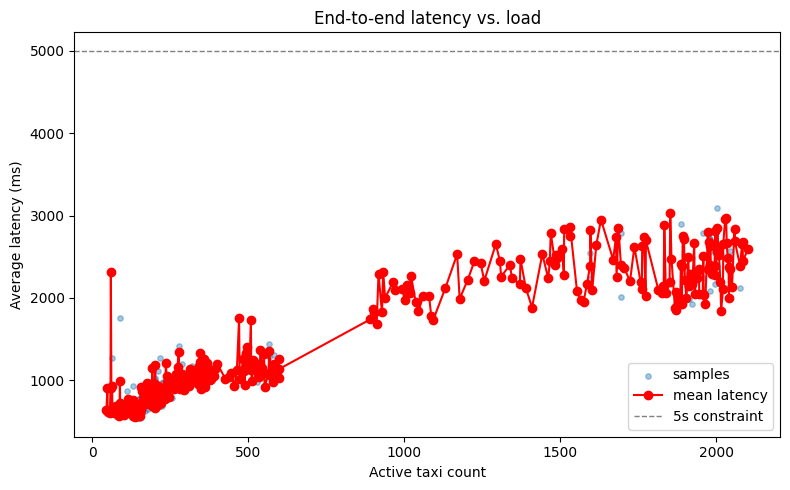

In [72]:

# raw scatter — shows spread/variance at each load level
plt.figure(figsize=(8, 5))
plt.scatter(df_load_act["active_taxi_count"], df_load_act["avg_latency_ms"], alpha=0.4, s=15, label="samples")

# mean latency per taxi count — the actual trend
trend = df_load_act.groupby("active_taxi_count")["avg_latency_ms"].mean().reset_index()
trend = trend.sort_values("active_taxi_count")
plt.plot(trend["active_taxi_count"], trend["avg_latency_ms"], color="red", marker="o", label="mean latency")

# reference line for your 5s latency constraint
plt.axhline(y=5000, color="gray", linestyle="--", linewidth=1, label="5s constraint")

plt.xlabel("Active taxi count")
plt.ylabel("Average latency (ms)")
plt.title("End-to-end latency vs. load")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# filter out outliers
# check if active taxi count also includes taxis that are parking our out of area (-> no speeding calculation necessary)

# Metrics per flink job

In [74]:
df_flink = pd.DataFrame()

for path in flink_paths:
    df = pd.read_csv(path)
    df_flink = pd.concat([df_flink, df])

df_flink

,timestamp_ms,vertex_name,vertex_id,0.numRecordsInPerSecond,0.numRecordsOutPerSecond,0.backPressuredTimeMsPerSecond,0.busyTimeMsPerSecond,load_level
0,1783859198925,Source: Kafka Taxi Source -> Parse JSON and Fi...,cbc357ccb763df2852fee8c4fc7d55f2,0.000000,0.000000,0,0.0,200
1,1783859198925,TumblingProcessingTimeWindows,306d8342cb5b2ad8b53f1be57f65bee8,0.000000,0.000000,0,0.0,200
2,1783859198925,"KeyedProcess -> (Map -> Store OOA to Redis, Map)",a11f7b3dcd72fbd94a295f0c524af5af,0.000000,0.000000,0,0.0,200
3,1783859198925,Area Active Alarms Snapshot,c3c9ede375c2027ffcf8fc21dcb1c364,0.000000,0.016667,0,0.0,200
4,1783859198925,Notify Area Violation: Writer -> Notify Area V...,d9350f7e40b0926985848318368d5d07,0.016667,0.000000,0,0.0,200
...,...,...,...,...,...,...,...,...
1678,1783862007373,Notify Area Violation: Writer -> Notify Area V...,d9350f7e40b0926985848318368d5d07,4.583333,0.000000,0,49.0,200
1679,1783862007373,Calculate Speed and Detect Speeding -> (Store ...,09d7d231d7c5000d8edd6d8c761a5909,79.750000,55.200000,0,343.0,200
1680,1783862007373,Total Distance Function,d3c7047dcd2df85109ccc9593d16fe63,207.633333,0.000000,0,246.0,200
1681,1783862007373,Speeding Active Alarms Snapshot,0c572a4fe8d5ca9bb4a4f542bda4488f,0.000000,0.016667,0,0.0,200


In [75]:
df_flink = df_flink[df_flink["0.numRecordsInPerSecond"].notna()]
df_flink

,timestamp_ms,vertex_name,vertex_id,0.numRecordsInPerSecond,0.numRecordsOutPerSecond,0.backPressuredTimeMsPerSecond,0.busyTimeMsPerSecond,load_level
0,1783859198925,Source: Kafka Taxi Source -> Parse JSON and Fi...,cbc357ccb763df2852fee8c4fc7d55f2,0.000000,0.000000,0,0.0,200
1,1783859198925,TumblingProcessingTimeWindows,306d8342cb5b2ad8b53f1be57f65bee8,0.000000,0.000000,0,0.0,200
2,1783859198925,"KeyedProcess -> (Map -> Store OOA to Redis, Map)",a11f7b3dcd72fbd94a295f0c524af5af,0.000000,0.000000,0,0.0,200
3,1783859198925,Area Active Alarms Snapshot,c3c9ede375c2027ffcf8fc21dcb1c364,0.000000,0.016667,0,0.0,200
4,1783859198925,Notify Area Violation: Writer -> Notify Area V...,d9350f7e40b0926985848318368d5d07,0.016667,0.000000,0,0.0,200
...,...,...,...,...,...,...,...,...
1678,1783862007373,Notify Area Violation: Writer -> Notify Area V...,d9350f7e40b0926985848318368d5d07,4.583333,0.000000,0,49.0,200
1679,1783862007373,Calculate Speed and Detect Speeding -> (Store ...,09d7d231d7c5000d8edd6d8c761a5909,79.750000,55.200000,0,343.0,200
1680,1783862007373,Total Distance Function,d3c7047dcd2df85109ccc9593d16fe63,207.633333,0.000000,0,246.0,200
1681,1783862007373,Speeding Active Alarms Snapshot,0c572a4fe8d5ca9bb4a4f542bda4488f,0.000000,0.016667,0,0.0,200


In [100]:
df_flink["0.busyTimeMsPerSecond"].describe()

count    4662.000000
mean       47.955813
std        96.418228
min         0.000000
25%         0.000000
50%         5.000000
75%        38.000000
max       447.000000
Name: 0.busyTimeMsPerSecond, dtype: float64

In [80]:
merged = pd.merge_asof(
    df_load_act.sort_values("timestamp_ms"),
    df_flink.sort_values("timestamp_ms"),
    on="timestamp_ms",
    by="load_level",       # only match within the same test run
    direction="nearest",
    tolerance=3000,
).dropna(subset=["vertex_name"])

/tmp/ipykernel_5485/2010361961.py:20: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


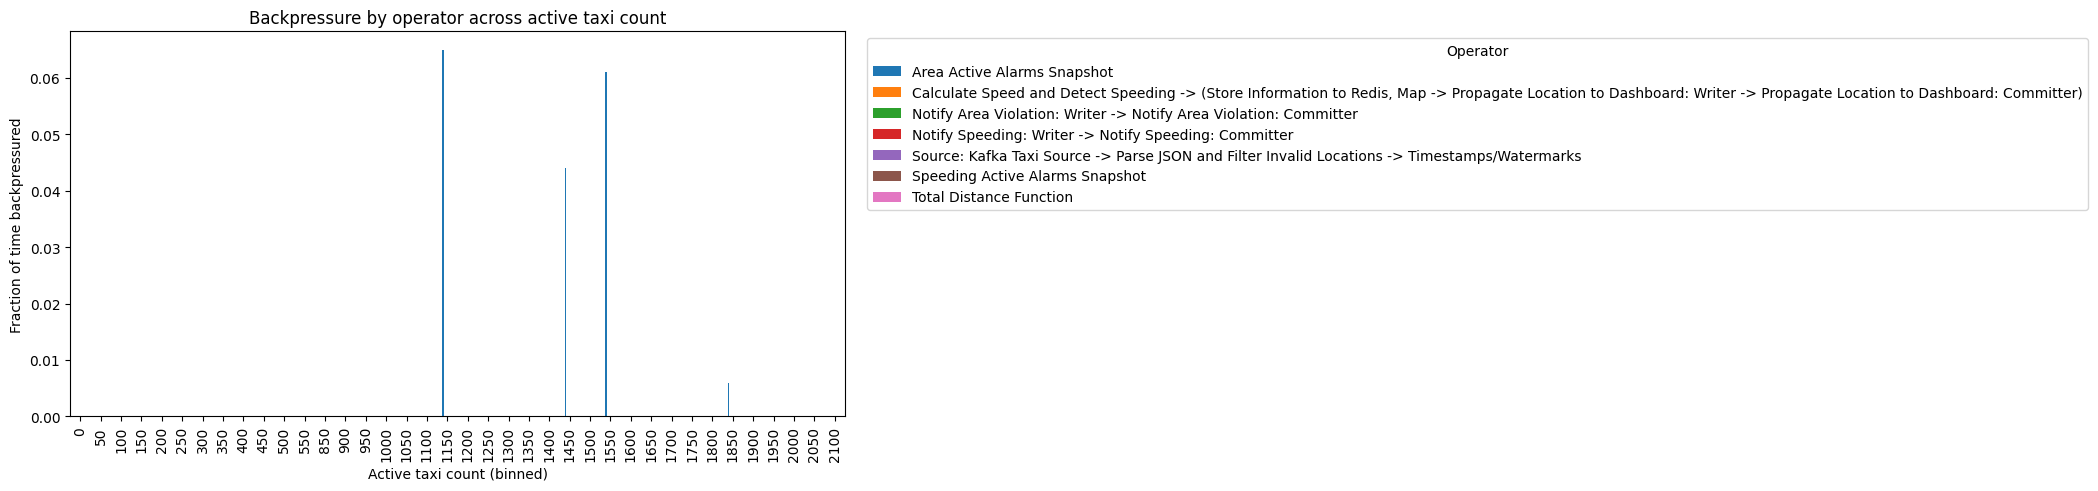

                        vertex_name  backpressure_ratio  throughput_gap
97  Speeding Active Alarms Snapshot                 0.0             0.0


In [98]:
BIN_SIZE = 50  # adjust based on your data's spread, e.g. 50 for finer resolution

merged["taxi_bucket"] = (merged["active_taxi_count"] // BIN_SIZE * BIN_SIZE).astype(int)

# ---- Backpressure analysis ----
op_summary = merged.groupby(["taxi_bucket", "vertex_name"]).agg(
    mean_in=("0.numRecordsInPerSecond", "mean"),
    mean_out=("0.numRecordsOutPerSecond", "mean"),
    mean_backpressure=("0.backPressuredTimeMsPerSecond", "mean"),
).reset_index()
op_summary["backpressure_ratio"] = op_summary["mean_backpressure"] / 1000
op_summary["throughput_gap"] = op_summary["mean_in"] - op_summary["mean_out"]

pivot_bp = op_summary.pivot(index="taxi_bucket", columns="vertex_name", values="backpressure_ratio")
pivot_bp.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Active taxi count (binned)")
plt.ylabel("Fraction of time backpressured")
plt.title("Backpressure by operator across active taxi count")
plt.legend(title="Operator", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# which operator is worst at the highest observed taxi count?
highest_bucket = op_summary["taxi_bucket"].max()
worst = op_summary[op_summary["taxi_bucket"] == highest_bucket].sort_values("backpressure_ratio", ascending=False)
print(worst[["vertex_name", "backpressure_ratio", "throughput_gap"]])

Backpressure is not very useful for our case (it also depends on the CPU)

/tmp/ipykernel_5485/4164073740.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


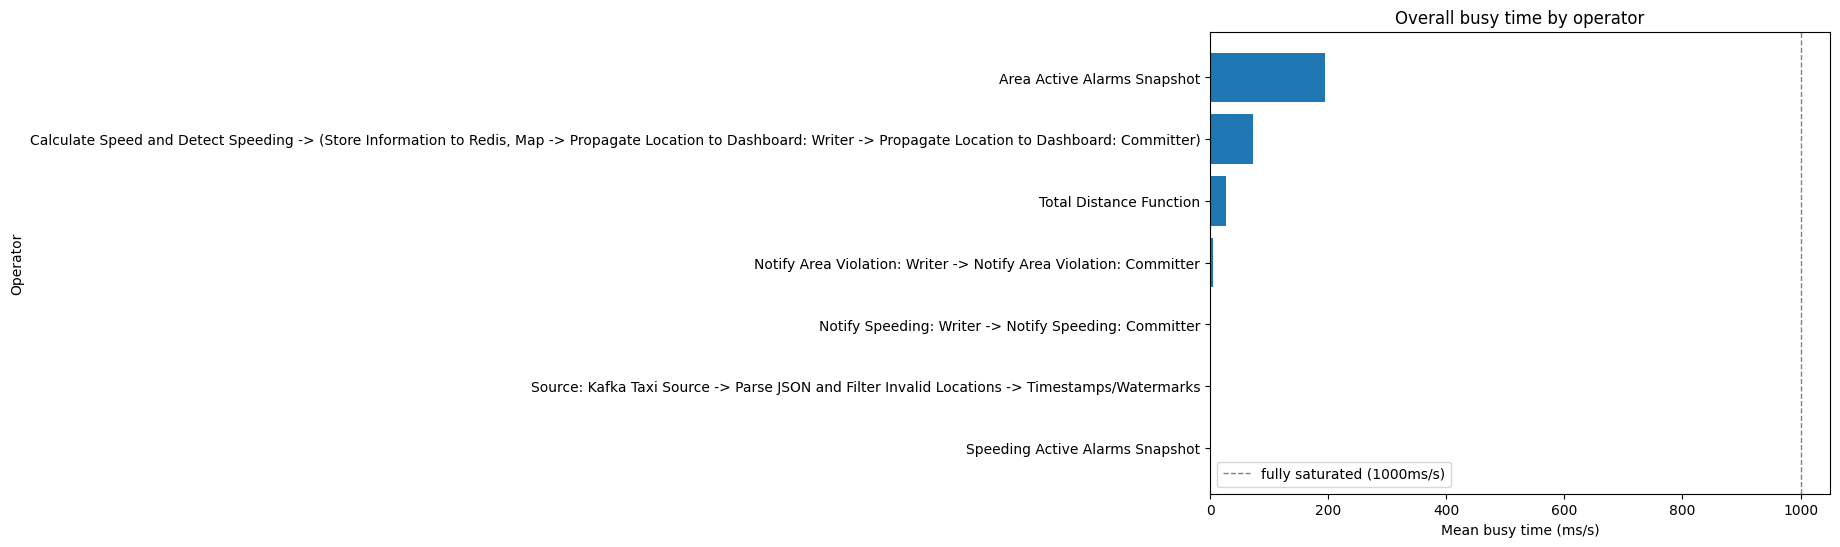

In [101]:
# looking at which operator does most of the work
# total (mean) busy time per operator, across the whole dataset
total_busy = merged.groupby("vertex_name")["0.busyTimeMsPerSecond"].mean().sort_values()

plt.figure(figsize=(8, 6))
plt.barh(total_busy.index, total_busy.values, color="tab:blue")
plt.xlabel("Mean busy time (ms/s)")
plt.ylabel("Operator")
plt.title("Overall busy time by operator")
plt.axvline(x=1000, color="gray", linestyle="--", linewidth=1, label="fully saturated (1000ms/s)")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_5485/1407027305.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


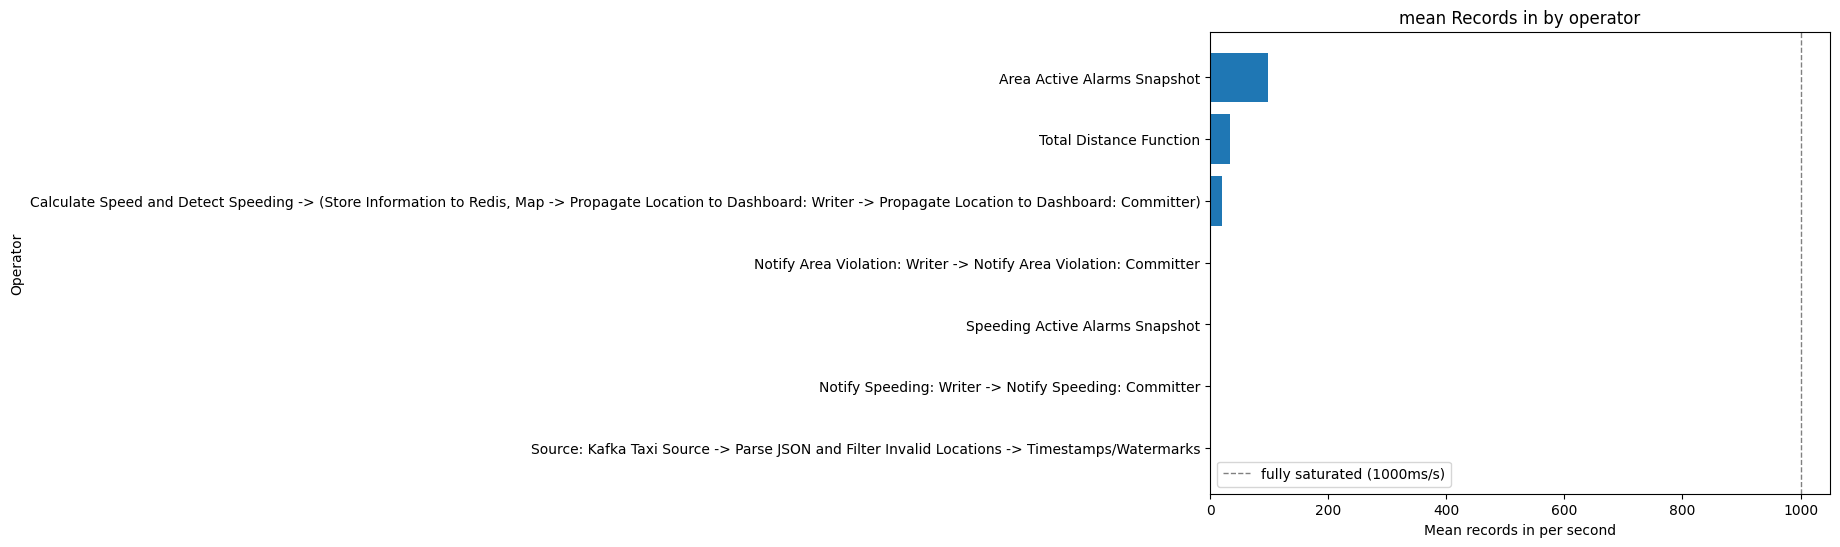

In [103]:
total_in = merged.groupby("vertex_name")["0.numRecordsInPerSecond"].mean().sort_values()

plt.figure(figsize=(8, 6))
plt.barh(total_in.index, total_in.values, color="tab:blue")
plt.xlabel("Mean records in per second")
plt.ylabel("Operator")
plt.title("mean Records in by operator")
plt.axvline(x=1000, color="gray", linestyle="--", linewidth=1, label="fully saturated (1000ms/s)")
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_5485/88723086.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


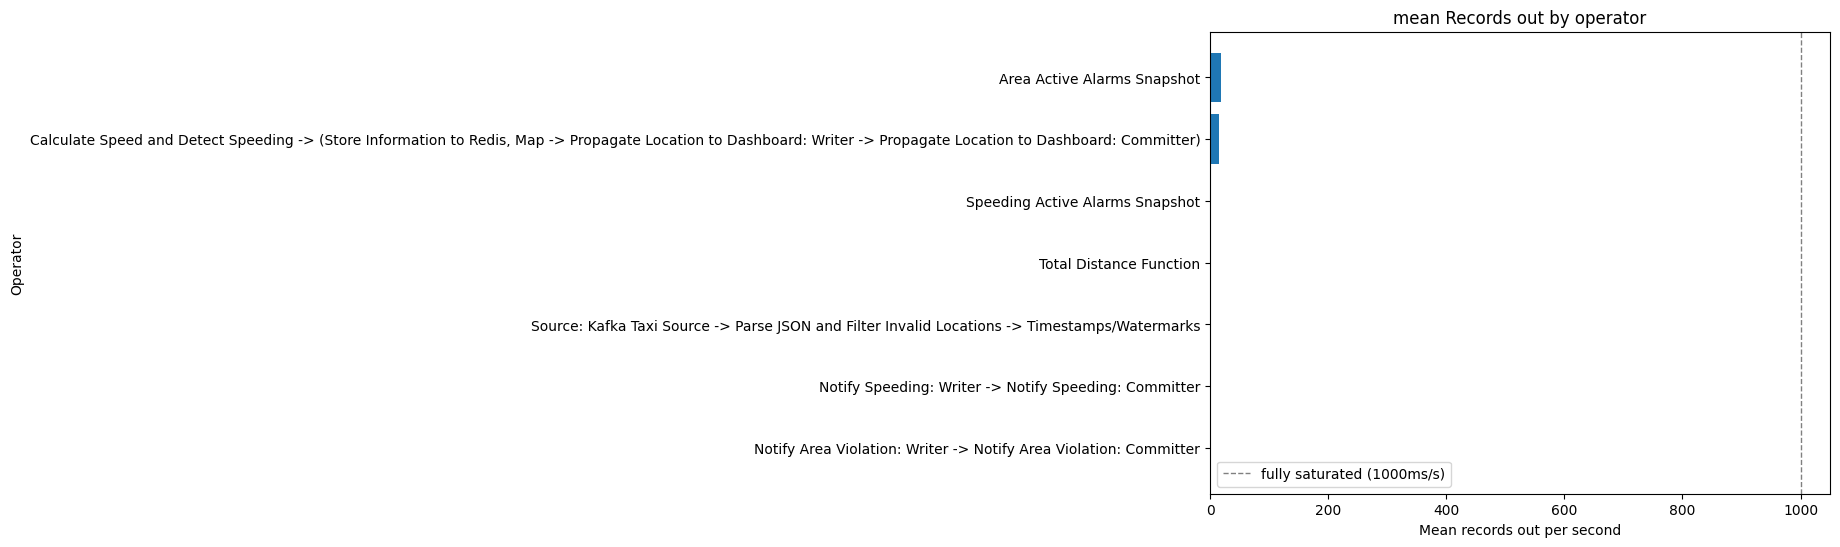

In [104]:
total_out = merged.groupby("vertex_name")["0.numRecordsOutPerSecond"].mean().sort_values()

plt.figure(figsize=(8, 6))
plt.barh(total_out.index, total_out.values, color="tab:blue")
plt.xlabel("Mean records out per second")
plt.ylabel("Operator")
plt.title("mean Records out by operator")
plt.axvline(x=1000, color="gray", linestyle="--", linewidth=1, label="fully saturated (1000ms/s)")
plt.legend()
plt.tight_layout()
plt.show()

# Combine both

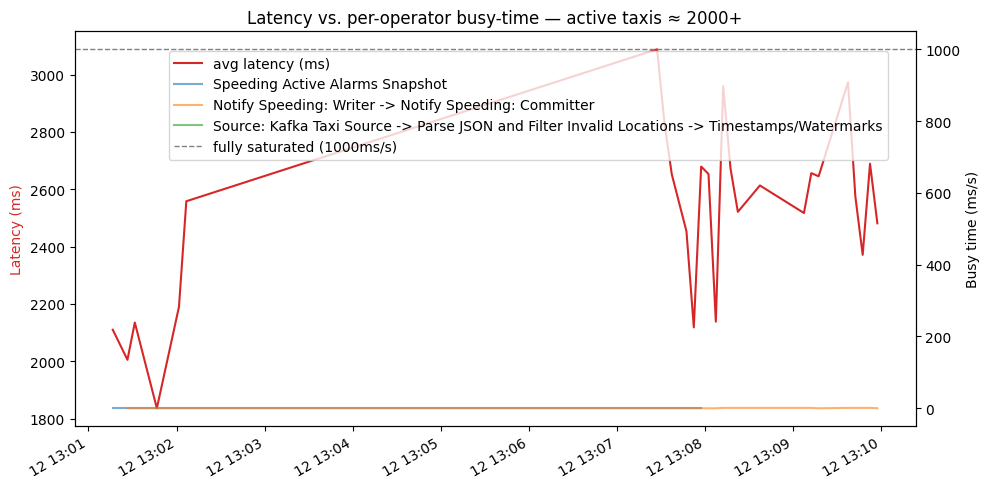

In [95]:
MIN_SAMPLES = 20  # adjust based on what value_counts() shows you

bucket_counts = merged["taxi_bucket"].value_counts()
valid_buckets = bucket_counts[bucket_counts >= MIN_SAMPLES].index
highest_bucket = valid_buckets.max()

# focus on your highest observed taxi bucket, plot latency and one operator's busy-time over time together
run = merged[merged["taxi_bucket"] == highest_bucket]
run["timestamp"] = pd.to_datetime(run["timestamp_ms"], unit="ms")

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(run["timestamp"], run["avg_latency_ms"], color="tab:red", label="avg latency (ms)")
ax1.set_ylabel("Latency (ms)", color="tab:red")

ax2 = ax1.twinx()
for vertex in run["vertex_name"].unique():
    v = run[run["vertex_name"] == vertex].sort_values("timestamp")
    ax2.plot(v["timestamp"], v["0.busyTimeMsPerSecond"], alpha=0.6, label=vertex)
ax2.set_ylabel("Busy time (ms/s)")
ax2.axhline(y=1000, color="gray", linestyle="--", linewidth=1, label="fully saturated (1000ms/s)")

fig.autofmt_xdate()  # angle the date labels so they don't overlap
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.title(f"Latency vs. per-operator busy-time — active taxis ≈ {highest_bucket}+")
plt.tight_layout()
plt.show()

In [92]:
print(run["vertex_name"].value_counts())

vertex_name
Notify Speeding: Writer -> Notify Speeding: Committer                                            22
Speeding Active Alarms Snapshot                                                                   3
Source: Kafka Taxi Source -> Parse JSON and Filter Invalid Locations -> Timestamps/Watermarks     1
Name: count, dtype: int64


In [88]:
merged["taxi_bucket"].value_counts().sort_index()

taxi_bucket
0       38
100     97
200     64
300     61
400     15
500     35
800      2
900      9
1000    11
1100     3
1200     5
1300     7
1400     9
1500    12
1600     9
1700     9
1800    22
1900    33
2000    26
2100     1
Name: count, dtype: int64